### **Predictor diagnostics** — which predictors work, and where

Follow-up to the readout: before adding predictors, find out which of today's work, in which cities, and
where they stop working. The model is the one in `02_regression_prediction` (LightGBM, `selected_v1` + agency
anchor, tuned), scored **leave-one-city-out (LOCO)**. Predictors are read by **family**
(`diagnostics.feature_family`): agency anchor, demographic, property distress, stores, transit, imagery,
roadway, neighbourhood.

**Three lenses** — each answers a different question, and they can disagree:

| lens | question | how | caveat |
|---|---|---|---|
| **usage** | how far does the model move predictions with this family? | grouped mean \|SHAP\| on held-out BGs, as a share | heavy use is not proof of value |
| **worth** | how much accuracy is lost without it? | refit LOCO without the family (3 seeds), full minus dropped | *unique* contribution only: a family whose signal another family also carries scores low |
| **direction** | inside a city, are the blocks the family pushes up the ones with more crime? | within-city Spearman of the family's SHAP vs observed log rate | negative = the relationship learned elsewhere runs the wrong way here |

Sections: **1** usage · **2** worth · **3** direction · **4** the three together · **5** Kansas City (works)
vs New York (doesn't), property · **6** Kansas City on total crime · **7** takeaways.
Logic lives in `src/regression_modelling/models/attribution.py`; figures go to `docs/images/05/`.

In [4]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import contextlib
import io
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
_root = next(p for p in [_here, *_here.parents] if (p / "src").is_dir())
sys.path.insert(0, str(_root / "src"))

from regression_modelling.models import attribution, diagnostics, figures
from regression_modelling.models.dataset import load_pooled_table, predictor_set, target_pool
from regression_modelling.models.metrics import scorecard, scorecard_by_city
from regression_modelling.models.training import TUNED_GBM_PARAMS
from regression_modelling.models.tuning import run_loco_parallel

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="An input array is constant")

FIG_DIR = _root / "docs" / "images" / "05"
SAVE_FIGS = True


def show(fig, name):
    """Save ``fig`` as FIG_DIR/name.png (if SAVE_FIGS) and display it."""
    if SAVE_FIGS:
        figures.save(fig, name, FIG_DIR)
    plt.show()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
CATS = ["wprop", "wtotal"]
PARAMS = TUNED_GBM_PARAMS["selected_v1"]
SEEDS = (0, 1, 2)
FOCUS = ["kansas_city", "new_york"]          # works vs doesn't (property)
CITIES, POOL, PREDS, RUN, SH = {}, {}, {}, {}, {}
with contextlib.redirect_stdout(io.StringIO()):
    for cat in CATS:
        CITIES[cat] = target_pool(cat)
        POOL[cat] = load_pooled_table(CITIES[cat])
        PREDS[cat] = predictor_set("selected_v1+agency", cat)
        RUN[cat] = run_loco_parallel(POOL[cat], cat, PREDS[cat], params=PARAMS, keep_fits=True)
        SH[cat] = diagnostics.loco_shap(RUN[cat])
BY_CITY = {cat: scorecard_by_city(RUN[cat]) for cat in CATS}
pd.DataFrame({cat: scorecard(RUN[cat])[["n", "r2_pooled", "r2_city", "spearman_city", "recall@10_city"]]
              for cat in CATS}).T

,n,r2_pooled,r2_city,spearman_city,recall@10_city
wprop,19978.0,0.429,0.355,0.610,0.428
wtotal,8667.0,0.393,0.321,0.639,0.394


### 1 · Usage — what the model leans on

Grouped |SHAP| per family as a share of the total (same numbers as `02` §4), overall and per held-out city.

,wprop,wtotal
agency anchor,24%,7%
property distress,20%,33%
transit,16%,16%
demographic,12%,13%
neighbourhood,10%,11%
roadway,9%,9%
stores,5%,6%
imagery,4%,4%


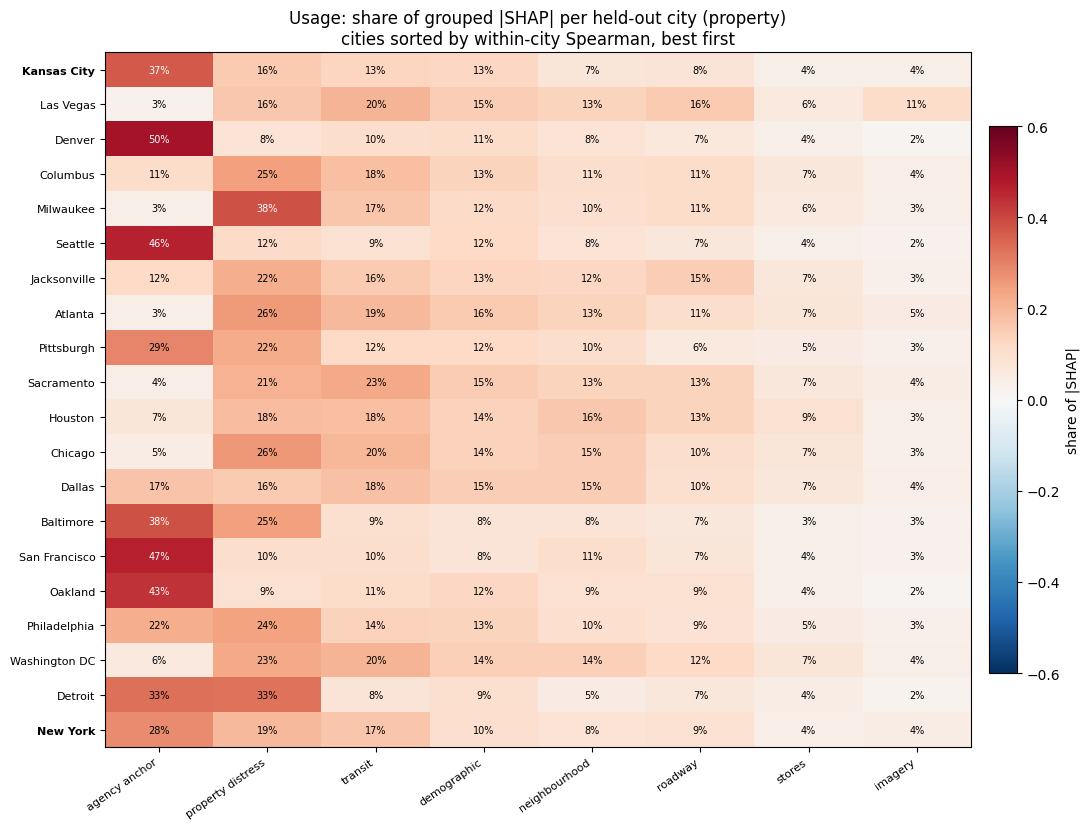

In [6]:
USE = {cat: diagnostics.shap_importance(SH[cat], by_family=True) for cat in CATS}
USE_CITY = {cat: diagnostics.shap_importance(SH[cat], by_family=True, by_city=True) for cat in CATS}
USE_CITY = {cat: t.div(t.sum(axis=1), axis=0) for cat, t in USE_CITY.items()}
FAM_ORDER = (USE["wprop"] / USE["wprop"].sum()).sort_values(ascending=False).index.tolist()
display(pd.DataFrame({cat: USE[cat] / USE[cat].sum() for cat in CATS}).loc[FAM_ORDER]
        .style.format("{:.0%}"))
_u = USE_CITY["wprop"].loc[BY_CITY["wprop"].sort_values("spearman", ascending=False).index, FAM_ORDER]
show(figures.diverging_heatmap(_u, fmt="{:.0%}", highlight=FOCUS, vmax=0.6,
                               title="Usage: share of grouped |SHAP| per held-out city (property)\n"
                                     "cities sorted by within-city Spearman, best first",
                               cbar_label="share of |SHAP|"),
     "usage_city_family_wprop")

**Read — usage.**

- **Overall it is the same picture as `02`.** For property crime: anchor 24%, property distress 20%, transit 16%,
  demographic 12%, neighbourhood 10%, roadway 9%, stores 5%, imagery 4%. Total crime is the same except
  that the anchor falls to 7% and property distress rises to 33%.
- **What varies by city is the anchor's share, not the mix of block-level families.** The anchor takes 37–50% in Kansas City, Denver,
  Seattle, San Francisco and Oakland, but only 3–6% in Las Vegas, Milwaukee, Atlanta, Chicago and DC. The block-level families
  keep roughly the same proportions everywhere.
- **Kansas City and New York use the model almost identically:** anchor 37% vs 28%, property distress 16% vs 19%,
  transit 13% vs 17%, demographic 13% vs 10%. So the model is not doing anything different in New York. Whatever
  goes wrong there, it is not which predictors the model leans on (§5).

### 2 · Worth — what is lost without each family

For each family, refit all LOCO folds **without** it and score the same BGs (rows complete in every
predictor). Three LightGBM seeds per configuration; whiskers are ±1 SD over seeds, i.e. how much of a
gap is just bagging noise. Positive = the model is worse without the family. This is the family's
**unique** contribution: if two families carry the same signal, dropping either costs little.

In [4]:
DROP = {}
for cat in CATS:
    with contextlib.redirect_stdout(io.StringIO()):
        DROP[cat] = attribution.family_dropout(POOL[cat], cat, PREDS[cat], params=PARAMS, seeds=SEEDS)
WORTH = {cat: attribution.dropout_deltas(DROP[cat]) for cat in CATS}
for cat in CATS:
    print(cat); display(WORTH[cat])

wprop


,d_r2_pooled,d_r2_city,d_spearman_city,d_recall@10_city,sd_r2_pooled,sd_r2_city,sd_spearman_city,sd_recall@10_city,cities_helped
agency anchor,1.508e-01,0.121,2.907e-03,-1.106e-02,0.008,2.192e-03,1.829e-03,0.007,14
property distress,7.315e-02,0.039,3.295e-02,-1.051e-02,0.004,1.251e-03,1.478e-03,0.008,14
demographic,4.970e-02,0.065,1.793e-02,1.293e-02,0.004,1.190e-03,1.285e-03,0.007,19
transit,3.369e-02,0.033,2.115e-02,1.317e-02,0.005,6.039e-04,4.503e-04,0.003,18
neighbourhood,1.138e-02,0.007,8.026e-03,5.094e-03,0.009,3.753e-03,1.999e-04,0.003,12
stores,7.175e-03,0.004,5.344e-03,6.349e-03,0.003,1.483e-03,8.764e-04,0.003,12
imagery,-1.322e-04,0.001,8.557e-05,-4.110e-04,0.003,4.165e-04,8.363e-04,0.007,13
roadway,-1.078e-02,0.012,1.006e-02,1.978e-03,0.003,2.663e-04,1.180e-03,0.002,15


wtotal


,d_r2_pooled,d_r2_city,d_spearman_city,d_recall@10_city,sd_r2_pooled,sd_r2_city,sd_spearman_city,sd_recall@10_city,cities_helped
property distress,0.074,4.902e-02,6.679e-02,2.078e-02,3.207e-03,4.452e-03,2.707e-03,2.711e-03,7
transit,0.053,5.097e-02,2.480e-02,1.825e-02,5.904e-03,4.203e-03,1.664e-03,9.635e-03,9
roadway,0.016,1.996e-02,7.401e-03,-8.399e-03,8.549e-04,4.300e-03,1.229e-03,6.106e-03,10
demographic,0.012,2.807e-02,1.040e-02,-2.308e-03,1.746e-03,4.107e-03,2.344e-04,7.532e-04,8
agency anchor,0.007,8.450e-04,3.643e-04,-1.103e-02,2.198e-03,9.730e-04,1.973e-03,2.903e-03,6
neighbourhood,0.005,1.135e-02,5.300e-03,1.435e-02,1.221e-03,3.635e-03,1.122e-03,1.118e-02,7
imagery,0.003,3.465e-03,8.723e-04,-1.217e-02,2.377e-03,4.422e-03,6.937e-04,1.164e-02,6
stores,0.001,4.047e-03,6.062e-03,2.014e-04,6.179e-04,7.070e-04,6.766e-05,1.195e-02,7


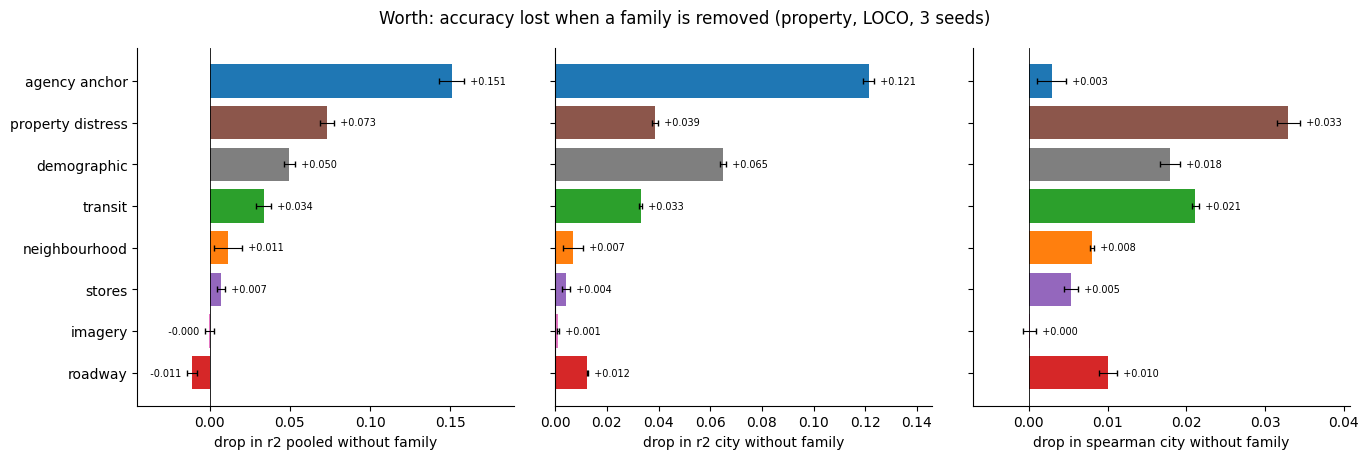

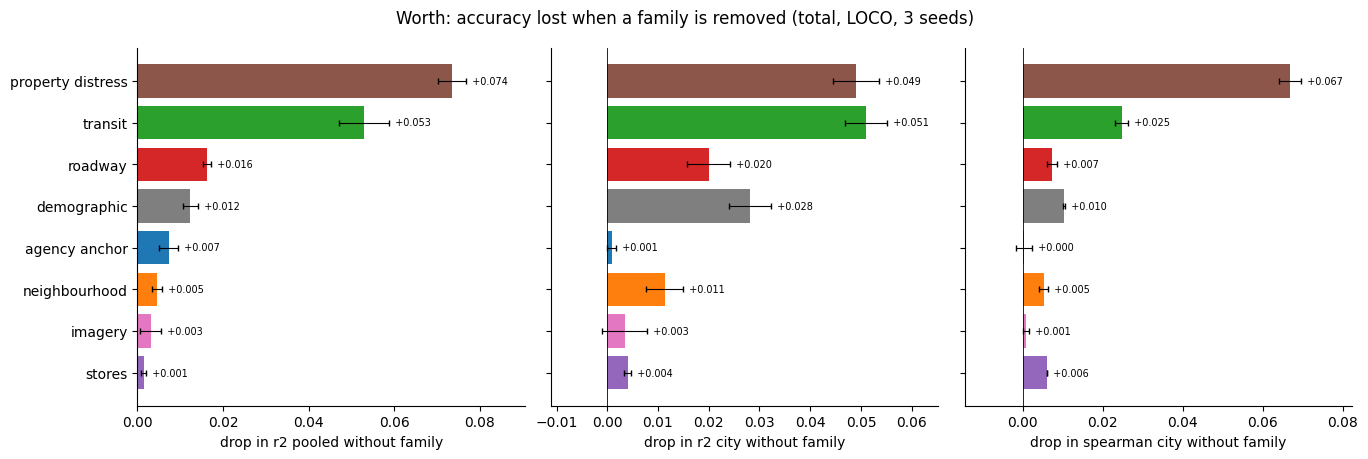

In [5]:
for cat, name in [("wprop", "property"), ("wtotal", "total")]:
    show(figures.dropout_bars(WORTH[cat], metrics=("r2_pooled", "r2_city", "spearman_city"),
                              title=f"Worth: accuracy lost when a family is removed ({name}, LOCO, 3 seeds)"),
         f"dropout_{cat}")

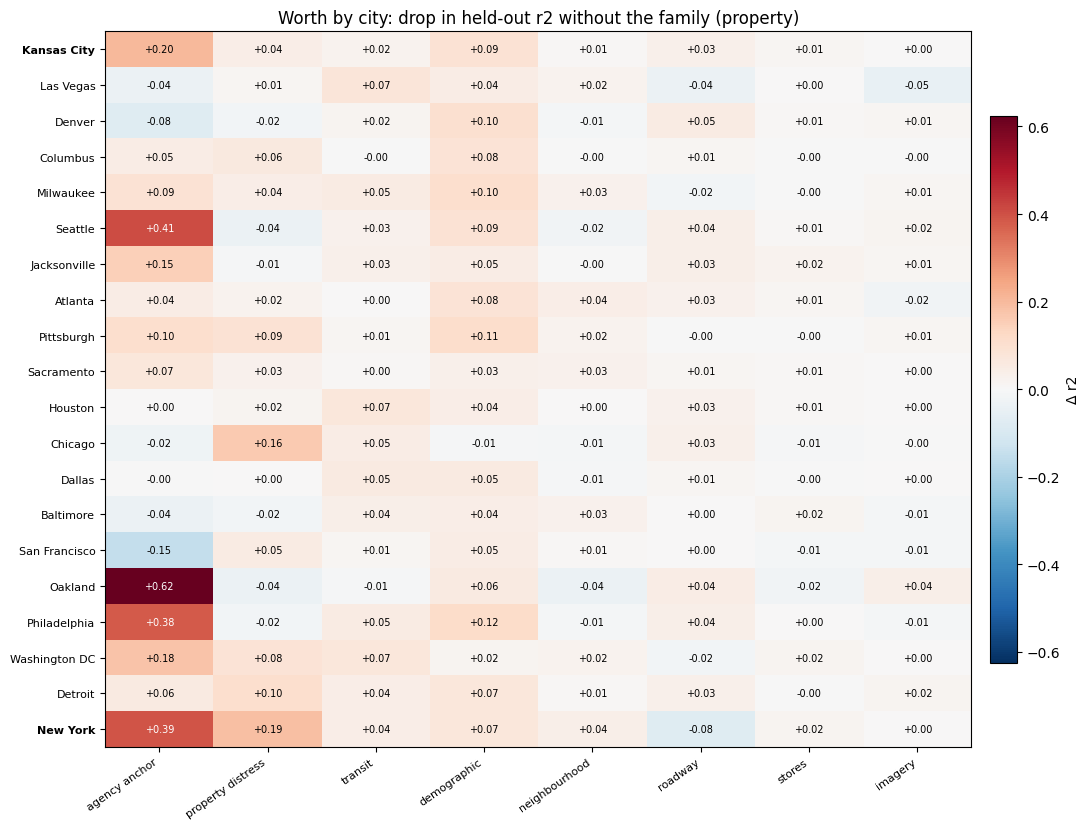

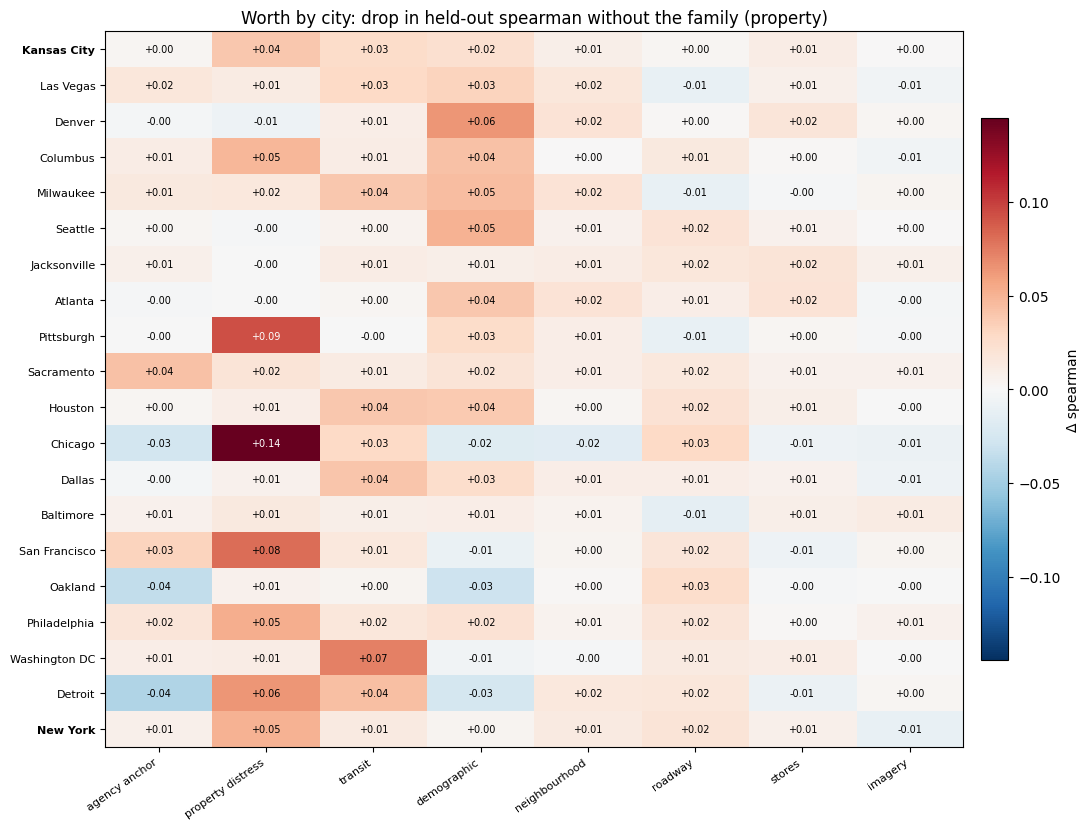

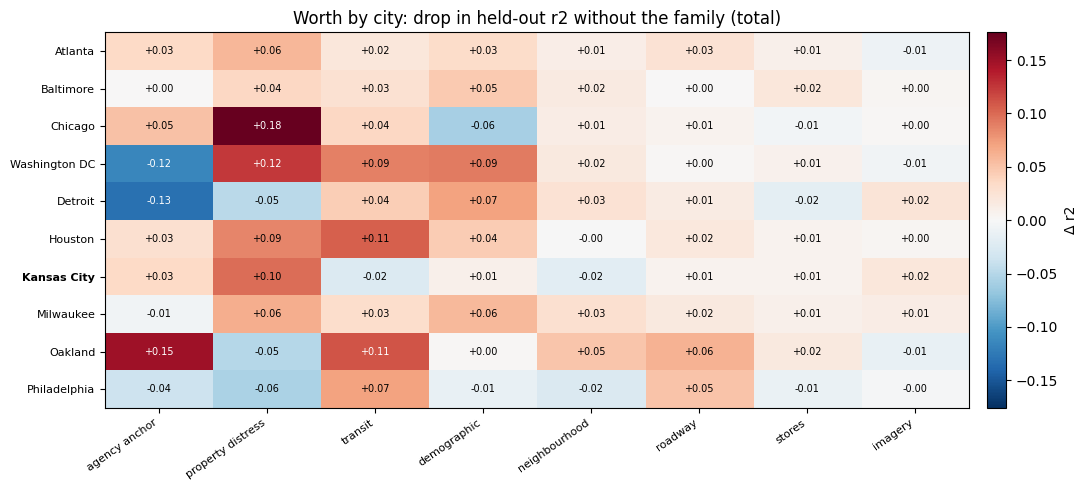

In [6]:
WORTH_CITY = {(cat, m): attribution.dropout_by_city(DROP[cat], m)
              for cat in CATS for m in ("r2", "spearman")}
_order = BY_CITY["wprop"].sort_values("spearman", ascending=False).index
for m in ("r2", "spearman"):
    show(figures.diverging_heatmap(WORTH_CITY[("wprop", m)].loc[_order, FAM_ORDER], highlight=FOCUS,
                                   title=f"Worth by city: drop in held-out {m} without the family (property)",
                                   cbar_label=f"Δ {m}"),
         f"dropout_city_{m}_wprop")
show(figures.diverging_heatmap(WORTH_CITY[("wtotal", "r2")].loc[:, [f for f in FAM_ORDER if f in WORTH_CITY[("wtotal", "r2")]]],
                               title="Worth by city: drop in held-out r2 without the family (total)",
                               cbar_label="Δ r2", highlight=["kansas_city"]),
     "dropout_city_r2_wtotal")

**Read — worth (property, 20 cities).**

- **The anchor buys level, not ranking.** Removing it costs the most pooled r² (0.15) and city-mean r² (0.12), but
  almost nothing in Spearman (0.003). Its value is concentrated in a few cities: Oakland +0.62, New York +0.39,
  Seattle +0.41, Philadelphia +0.38. It *hurts* San Francisco (−0.15) and Denver (−0.08), where the agency rate is
  a poor guide to the block-group mean.
- **Ranking comes from the block families.** Their Spearman losses are: property distress 0.033, transit 0.021,
  demographic 0.018, roadway 0.010, neighbourhood 0.008, stores 0.005. All are well above the seed noise (SD ≤ 0.002).
  Demographic and transit help the most cities on r² (19/20 and 18/20).
- **Roadway helps most cities but hurts the pooled score.** It helps 15/20 cities, city-mean r² (+0.012) and Spearman (+0.010), yet pooled r² is
  *better without it* (−0.011). That is New York (−0.08 in the heatmap; 30% of rows): roadway pushes New York's level
  up (§5).
- **Imagery is worth nothing.** It is zero on every metric (|Δ| ≤ 0.001, inside seed noise).
- **Unique worth is small because the families overlap.** No single family costs more than 0.07 of the 0.43 pooled r². The
  neighbourhood features largely repeat their block-level versions (0.011).
- **Total crime (10 cities).** Property distress (0.074 pooled r², 0.067 Spearman) and transit (0.053) carry it. The
  anchor is worth almost nothing (0.007) with only 9 training agencies per fold. Roadway helps 10/10 cities.
- `recall@10_city` changes are within ±0.02 and about as large as their seed SD, so this notebook does not read them.

### 3 · Direction — does the family push the right blocks up, city by city?

Per held-out city: sum each BG's SHAP over the family's features (the push the family gives that block),
then take the Spearman correlation with the block's observed log rate. The anchor is left out: it is
constant inside a city, so it sets the level and cannot rank. A family can rank well on its own push
even if its overall weight is small; a **negative** value means the family systematically pushes up the
safer blocks in that city.

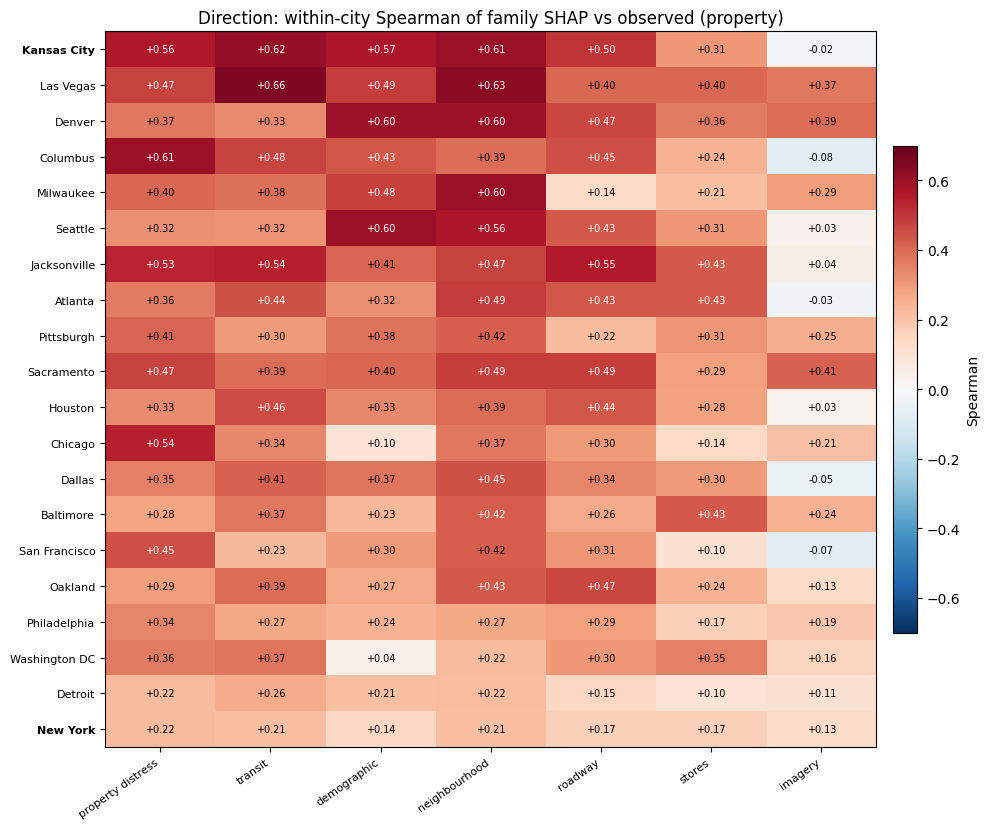

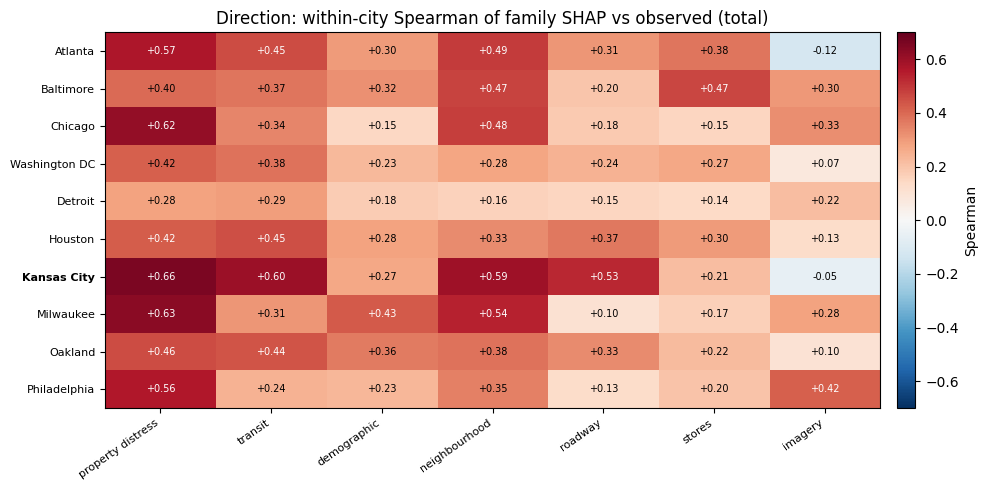

In [7]:
DIR = {cat: attribution.family_direction(SH[cat], RUN[cat].scored, cat) for cat in CATS}
_fams = [f for f in FAM_ORDER if f != "agency anchor"]
show(figures.diverging_heatmap(DIR["wprop"].loc[_order, _fams], highlight=FOCUS, vmax=0.7,
                               title="Direction: within-city Spearman of family SHAP vs observed (property)",
                               cbar_label="Spearman"),
     "direction_wprop")
show(figures.diverging_heatmap(DIR["wtotal"].loc[:, [f for f in _fams if f in DIR["wtotal"]]],
                               highlight=["kansas_city"], vmax=0.7,
                               title="Direction: within-city Spearman of family SHAP vs observed (total)",
                               cbar_label="Spearman"),
     "direction_wtotal")

**Read — direction.**

- **No block family runs the wrong way in any city, except imagery.** Property distress, transit, demographic, neighbourhood,
  roadway and stores are positive in 20/20 cities (property) and 10/10 (total). Imagery is negative in 5/20
  (Kansas City, Columbus, Atlanta, Dallas, San Francisco), always near zero (−0.02 to −0.08).
- **So where the predictors "don't work", they are weak, not reversed.** In the weak cities *every* family is weak
  together. New York is 0.13–0.22 across all families and Detroit 0.10–0.26, against 0.31–0.62 in Kansas City and
  0.37–0.66 in Las Vegas. A failure across every family points at the city, not at one family.
- **There are two partial exceptions.** Demographic barely ranks in DC (0.04) and Chicago (0.10). Chicago is carried by property
  distress instead (0.54).

### 4 · The three lenses side by side

One row per family. `usage` = share of grouped |SHAP|; `Δ r2_pooled` / `Δ spearman` = worth (drop
without it); `cities helped` = held-out cities whose r² falls without it; `direction` = median
within-city Spearman, and `cities wrong way` = cities where it is negative.

In [8]:
def lens_table(cat):
    u = USE[cat] / USE[cat].sum()
    w = WORTH[cat]
    d = DIR[cat]
    return pd.DataFrame({
        "usage": u,
        "Δ r2_pooled": w["d_r2_pooled"], "Δ r2_city": w["d_r2_city"], "Δ spearman": w["d_spearman_city"],
        "cities helped": w["cities_helped"].astype(str) + f"/{len(CITIES[cat])}",
        "direction (median)": d.median(),
        "cities wrong way": (d < 0).sum().astype(int).astype(str) + f"/{len(CITIES[cat])}",
    }).loc[[f for f in FAM_ORDER if f in u.index]]


LENS = {cat: lens_table(cat) for cat in CATS}
for cat in CATS:
    print(cat); display(LENS[cat])

wprop


,usage,Δ r2_pooled,Δ r2_city,Δ spearman,cities helped,direction (median),cities wrong way
agency anchor,0.240,1.508e-01,0.121,2.907e-03,14/20,NaN,NaN
property distress,0.202,7.315e-02,0.039,3.295e-02,14/20,0.366,0/20
transit,0.156,3.369e-02,0.033,2.115e-02,18/20,0.378,0/20
demographic,0.117,4.970e-02,0.065,1.793e-02,19/20,0.353,0/20
neighbourhood,0.103,1.138e-02,0.007,8.026e-03,12/20,0.425,0/20
roadway,0.095,-1.078e-02,0.012,1.006e-02,15/20,0.371,0/20
stores,0.051,7.175e-03,0.004,5.344e-03,12/20,0.292,0/20
imagery,0.037,-1.322e-04,0.001,8.557e-05,13/20,0.129,5/20


wtotal


,usage,Δ r2_pooled,Δ r2_city,Δ spearman,cities helped,direction (median),cities wrong way
agency anchor,0.074,0.007,8.450e-04,3.643e-04,6/10,NaN,NaN
property distress,0.333,0.074,4.902e-02,6.679e-02,7/10,0.507,0/10
transit,0.163,0.053,5.097e-02,2.480e-02,9/10,0.378,0/10
demographic,0.127,0.012,2.807e-02,1.040e-02,8/10,0.275,0/10
neighbourhood,0.109,0.005,1.135e-02,5.300e-03,7/10,0.425,0/10
roadway,0.089,0.016,1.996e-02,7.401e-03,10/10,0.219,0/10
stores,0.062,0.001,4.047e-03,6.062e-03,7/10,0.219,0/10
imagery,0.043,0.003,3.465e-03,8.723e-04,6/10,0.173,2/10


**Read — the three lenses together.**

| role | families | evidence |
|---|---|---|
| **workhorses** | property distress, transit, demographic | 48% of usage; largest r² *and* Spearman worth; right direction in every city |
| **level-setter** | agency anchor | largest r² worth, ~0 ranking worth; decisive in Oakland, New York, Seattle and Philadelphia, harmful in San Francisco and Denver |
| **supporting** | roadway, neighbourhood, stores | 25% of usage; consistent direction; small unique worth (≤ 0.012 r², ≤ 0.010 Spearman). Roadway mis-levels New York |
| **dead weight** | imagery | 4% of usage, zero worth, weakest direction (wrong way in 5/20) |

Usage and worth disagree most for neighbourhood (10% of usage, about 0.01 of worth). The model uses those features, but the block-level
versions carry the same information.

### 5 · Kansas City vs New York (property)

Kansas City is among the best-ranked held-out cities; New York is the worst on within-city Spearman and
holds ~30% of the property BGs. First the city profile, then the three lenses by family, then feature by
feature.

,BGs,median rate /1k,SD log rate,level error,r2,spearman,recall@10
kansas_city,469.0,41.051,1.159,-0.111,0.558,0.754,0.574
new_york,6377.0,10.549,0.990,0.319,0.173,0.349,0.433


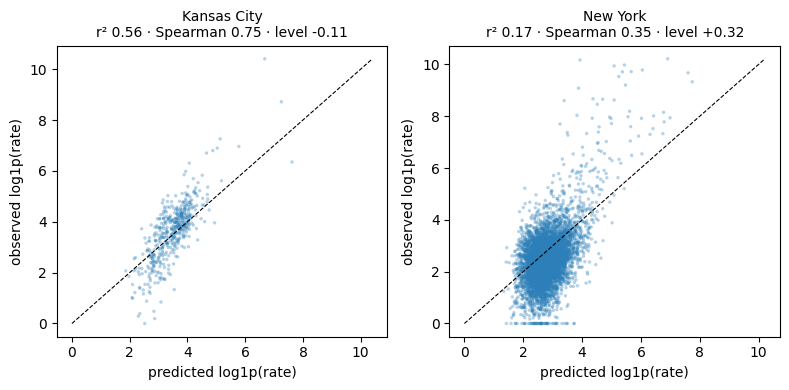

In [9]:
def city_profile(cat, cities):
    s = RUN[cat].scored
    rows = {}
    for c in cities:
        h = s[s["holdout_city"] == c]
        obs = np.log1p(h[f"{cat}_rate"].astype(float))
        rows[c] = {"BGs": len(h), "median rate /1k": h[f"{cat}_rate"].median(),
                   "SD log rate": obs.std(), "level error": h["y_pred"].mean() - obs.mean(),
                   **BY_CITY[cat].loc[c, ["r2", "spearman", "recall@10"]].to_dict()}
    return pd.DataFrame(rows).T


display(city_profile("wprop", FOCUS))
show(figures.pred_vs_obs(RUN["wprop"], FOCUS), "pred_vs_obs_kc_ny")

In [10]:
def family_lenses(cat, city):
    return pd.DataFrame({
        "usage": USE_CITY[cat].loc[city],
        "Δ r2 (drop)": WORTH_CITY[(cat, "r2")].loc[city],
        "Δ spearman (drop)": WORTH_CITY[(cat, "spearman")].loc[city],
        "direction": DIR[cat].loc[city],
    }).loc[[f for f in FAM_ORDER if f in USE_CITY[cat].columns]]


pd.concat({figures._label(c): family_lenses("wprop", c) for c in FOCUS}, axis=1).style.format("{:+.2f}")

**Feature by feature.** For each held-out city, using its LOCO model unchanged:
`shap_share` (usage), `perm_d_r2` / `perm_d_rho` (worth: the drop when the feature is shuffled among the
city's BGs, 5 repeats; correlated partners can cover, so this understates shared signal), `local_rho`
(Spearman of the raw feature with crime in the city) vs `others_rho` (median over the training cities),
`model_dir` (sign of the relationship the model applies: Spearman of feature vs its SHAP) and `agrees`,
and `city_pctile` (where the city's median value sits in the other cities' distribution; near 0 or 1 =
outside what the model trained on).

In [11]:
FT = {c: attribution.city_feature_table(RUN["wprop"], SH["wprop"], c) for c in FOCUS}
_cols = ["family", "shap_share", "perm_d_r2", "perm_d_rho", "local_rho", "others_rho", "model_dir",
         "agrees", "city_pctile"]
_fmt = {"shap_share": "{:.0%}", "city_pctile": "{:.2f}", **{k: "{:+.3f}" for k in
        ["perm_d_r2", "perm_d_rho", "local_rho", "others_rho", "model_dir"]}}
print("Kansas City"); display(FT["kansas_city"][_cols].style.format(_fmt, na_rep="–"))

Kansas City


,family,shap_share,perm_d_r2,perm_d_rho,local_rho,others_rho,model_dir,agrees,city_pctile
agency_lag_wprop_log,agency anchor,27%,–,–,–,–,–,–,0.93
vacant_pct_log,property distress,8%,+0.056,+0.026,+0.570,+0.330,+0.986,True,0.73
own_pct,demographic,6%,+0.138,+0.086,-0.552,-0.344,-0.973,True,0.65
transit_service_intensity_logc,transit,6%,+0.041,+0.032,+0.296,+0.299,+0.862,True,0.48
pop_est_5mile_log,demographic,6%,-0.006,-0.002,+0.503,+0.122,-0.048,False,0.03
own_pct_nbr,neighbourhood,4%,+0.064,+0.051,-0.572,-0.377,-0.987,True,0.66
clip_foreclosure_pct_lag6_log,property distress,3%,+0.018,+0.005,+0.297,+0.216,+0.959,True,0.66
roadway_arterial_density_log,roadway,2%,+0.024,+0.016,+0.393,+0.271,+0.968,True,0.37
lap_pct,demographic,2%,+0.024,+0.001,+0.408,+0.228,-0.888,False,0.33
moved1yr_pct,demographic,2%,+0.062,+0.009,+0.240,+0.202,+0.898,True,0.61


In [12]:
print("New York"); FT["new_york"][_cols].style.format(_fmt, na_rep="–")

New York


,family,shap_share,perm_d_r2,perm_d_rho,local_rho,others_rho,model_dir,agrees,city_pctile
agency_lag_wprop_log,agency anchor,20%,–,–,–,–,–,–,0.00
transit_service_intensity_logc,transit,9%,+0.064,+0.046,+0.167,+0.299,+0.885,True,0.48
own_pct_nbr,neighbourhood,7%,+0.001,+0.016,-0.172,-0.385,-0.964,True,0.18
own_pct,demographic,7%,+0.074,+0.011,-0.143,-0.347,-0.986,True,0.29
vacant_pct_log,property distress,6%,+0.027,+0.025,+0.221,+0.364,+0.931,True,0.20
clip_foreclosure_pct_lag6_log,property distress,4%,+0.006,+0.007,+0.025,+0.261,+0.966,True,0.25
roadway_nearest_interstate_m_log,roadway,3%,+0.015,+0.017,-0.136,-0.258,-0.943,True,0.31
roadway_arterial_density_log,roadway,3%,+0.005,+0.006,+0.161,+0.288,+0.685,True,0.82
hardscapes_pct_avg,imagery,3%,-0.001,-0.007,-0.111,-0.214,-0.779,True,0.48
transit_risky_stop_count_log,transit,3%,-0.001,+0.003,+0.206,+0.373,+0.912,True,0.51


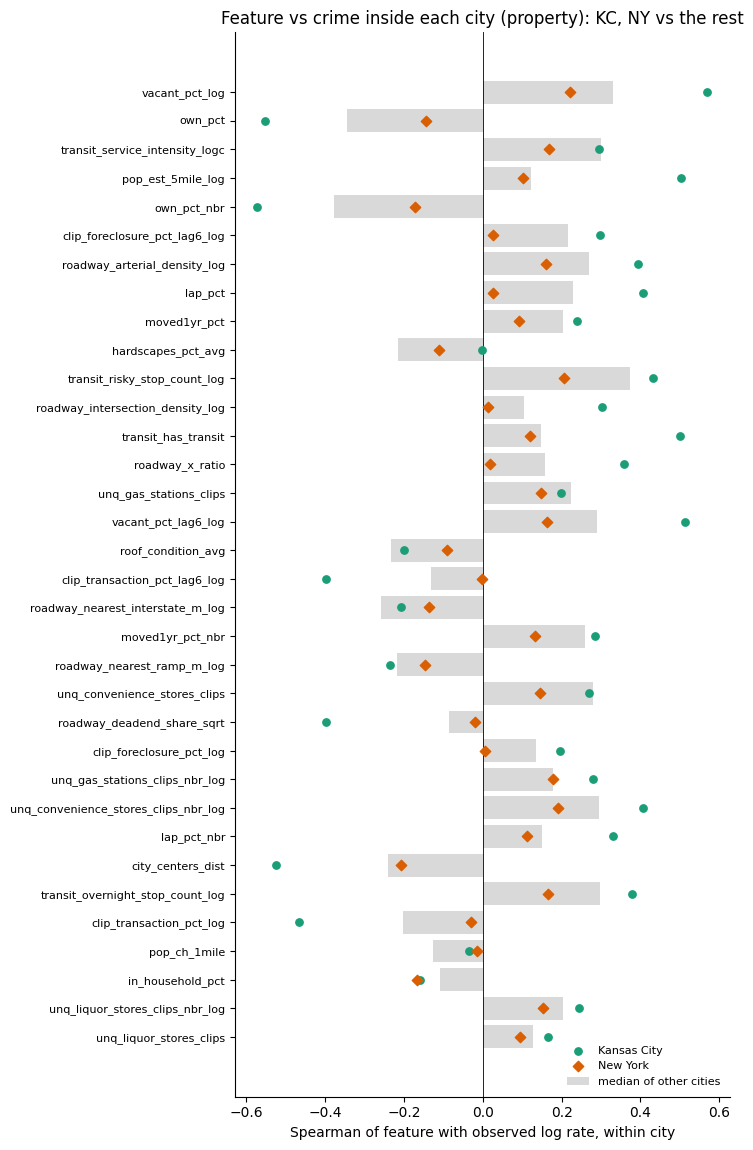

In [13]:
_feats = [f for f in FT["kansas_city"].index if np.isfinite(FT["kansas_city"].loc[f, "local_rho"])]
show(figures.feature_rho_dots(FT, _feats,
                              title="Feature vs crime inside each city (property): KC, NY vs the rest"),
     "feature_rho_kc_ny")

**Why is New York weak?** Two checks. (1) Is it one borough, or the mix of boroughs? Spearman of
predicted vs observed inside each borough, and after removing borough means. (2) Which families set its
level? Mean signed SHAP per family (`attribution.family_level_push`): with the fold's base they add up
to the city's mean prediction, so a family pushing up a city that is actually low is part of the level miss.

In [14]:
_BORO = {"36005": "Bronx", "36047": "Brooklyn", "36061": "Manhattan", "36081": "Queens",
         "36085": "Staten Island"}
_s = RUN["wprop"].scored
ny = _s[_s["holdout_city"] == "new_york"].assign(
    obs=lambda d: np.log1p(d["wprop_rate"].astype(float)),
    boro=lambda d: d["geoid"].astype(str).str[:5].map(_BORO))
_rho = lambda a, b: a.rank().corr(b.rank())
display(ny.groupby("boro").apply(lambda d: pd.Series({
    "BGs": len(d), "Spearman": _rho(d["y_pred"], d["obs"]),
    "obs mean": d["obs"].mean(), "pred mean": d["y_pred"].mean()})).round(2))
_dm = lambda c: ny[c] - ny.groupby("boro")[c].transform("mean")
print(f"New York Spearman: {_rho(ny['y_pred'], ny['obs']):.3f}; "
      f"after removing borough means: {_rho(_dm('y_pred'), _dm('obs')):.3f}")
PUSH = attribution.family_level_push(SH["wprop"], RUN["wprop"])
PUSH.loc[FOCUS + ["chicago", "philadelphia"]].T.round(3)

,BGs,Spearman,obs mean,pred mean
boro,,,,
Bronx,1106.0,0.34,2.87,2.87
Brooklyn,2068.0,0.41,2.32,2.85
Manhattan,1156.0,0.48,2.64,3.02
Queens,1719.0,0.15,2.47,2.63
Staten Island,328.0,0.46,1.88,2.66


New York Spearman: 0.349; after removing borough means: 0.351


holdout_city,kansas_city,new_york,chicago,philadelphia
agency anchor,0.493,-0.352,-0.028,0.213
demographic,-0.089,0.052,-0.014,-0.009
imagery,-0.002,0.001,0.007,-0.002
neighbourhood,-0.021,0.003,-0.045,-0.055
property distress,0.124,-0.228,0.122,-0.032
roadway,0.014,0.078,-0.005,0.002
stores,-0.008,-0.019,-0.015,-0.011
transit,-0.069,-0.043,0.026,0.037
_base,3.044,3.320,3.041,3.018
obs_mean,3.599,2.493,3.186,3.628


**Read — Kansas City vs New York.**

- **Profiles.**

  | city | BGs | median property crime per 1,000 | r² | Spearman | level |
  |---|---|---|---|---|---|
  | Kansas City | 469 | 41 | 0.56 | 0.75 | −0.11 |
  | New York | 6,377 | 10.5 (the lowest of the 20) | 0.17 | 0.35 | +0.32 |

- **Kansas City works because its crime follows the national pattern more steeply.** The signs match the rest, but the
  within-city correlations are stronger:

  | feature | Kansas City | median of other cities |
  |---|---|---|
  | vacancy | 0.57 | 0.33 |
  | `own_pct` | −0.55 | −0.34 |
  | `has_transit` | 0.50 | 0.15 |
  | distance to centre | −0.53 | −0.24 |
  | `x_ratio` | 0.36 | 0.16 |

  Its features mostly sit mid-range among the training cities (percentile 0.2–0.8), so every family except stores (0.31) ranks at 0.5–0.6.
- **New York fails because the same relationships are about half as strong:**

  | feature | New York | median of other cities |
  |---|---|---|
  | vacancy | 0.22 | 0.36 |
  | `own_pct` | −0.14 | −0.35 |
  | foreclosure in the 6 nearest neighbours (`_lag6`) | 0.03 | 0.26 |
  | intersection density | 0.01 | 0.13 |
  | `x_ratio` | 0.02 | 0.20 |
  | risky stops | 0.21 | 0.37 |

  The model applies the right sign to almost every feature (`agrees`), but the features say less about where New York's
  crime is. This holds inside every borough: Queens 0.15, Bronx 0.34, Brooklyn 0.41, Staten Island 0.46,
  Manhattan 0.48. Removing borough means leaves the Spearman unchanged (0.35), so the problem is not the mix of boroughs.
- **New York is also outside the training range.** It has the lowest agency rate (percentile 0.00), the highest 5-mile
  population (1.00) and the densest street grid (intersection density 0.87, arterials 0.82).
- **Level (the push table).** The training base is 3.32. The anchor pulls New York down 0.35 and property distress
  another 0.23, but roadway (+0.08) and demographic (+0.05) push it *up*, so a dense grid reads as risk. The net result is +0.32
  too high, most of it in Staten Island (+0.78), Brooklyn (+0.53) and Manhattan (+0.38). Hence dropping roadway *raises*
  New York's r² by 0.08, and most of the anchor's and property distress's worth there (0.39, 0.19) is levelling.
- **Caveat on `model_dir` disagreements.** `lap_pct` and `pop_est_5mile_log` disagree in both cities. That is a conditional effect
  (net of `own_pct` and density) differing from the marginal one, not an error.

### 6 · Kansas City on total crime

New York has no total-crime target, so the cross-check is Kansas City alone: do the same families carry it?

In [15]:
display(city_profile("wtotal", ["kansas_city"]))
display(family_lenses("wtotal", "kansas_city").style.format("{:+.2f}"))
FT_T = attribution.city_feature_table(RUN["wtotal"], SH["wtotal"], "kansas_city")
FT_T[_cols].head(15).style.format(_fmt, na_rep="–")

,BGs,median rate /1k,SD log rate,level error,r2,spearman,recall@10
kansas_city,469.0,47.593,1.286,-0.475,0.473,0.781,0.447


,usage,Δ r2 (drop),Δ spearman (drop),direction
agency anchor,+0.03,+0.03,+0.00,+nan
property distress,+0.35,+0.10,+0.05,+0.66
transit,+0.22,-0.02,+0.03,+0.60
demographic,+0.13,+0.01,+0.01,+0.27
neighbourhood,+0.10,-0.02,+0.00,+0.59
roadway,+0.09,+0.01,+0.00,+0.53
stores,+0.05,+0.01,+0.00,+0.21
imagery,+0.03,+0.02,-0.00,-0.05


,family,shap_share,perm_d_r2,perm_d_rho,local_rho,others_rho,model_dir,agrees,city_pctile
vacant_pct_log,property distress,12%,+0.074,+0.037,+0.645,+0.445,+0.970,True,0.59
transit_service_intensity_logc,transit,9%,+0.049,+0.046,+0.292,+0.355,+0.701,True,0.47
clip_foreclosure_pct_lag6_log,property distress,8%,+0.030,+0.022,+0.482,+0.387,+0.952,True,0.49
own_pct_nbr,neighbourhood,7%,+0.061,+0.043,-0.558,-0.383,-0.987,True,0.63
own_pct,demographic,7%,+0.056,+0.032,-0.508,-0.331,-0.977,True,0.62
vacant_pct_lag6_log,property distress,4%,+0.017,+0.011,+0.606,+0.470,+0.810,True,0.64
pop_est_5mile_log,demographic,4%,-0.006,-0.003,+0.423,+0.089,-0.629,False,0.02
transit_has_transit,transit,4%,+0.012,+0.011,+0.490,+0.139,+0.808,True,0.55
clip_foreclosure_pct_log,property distress,3%,-0.001,+0.003,+0.336,+0.268,+0.723,True,0.48
roadway_nearest_interstate_m_log,roadway,3%,+0.004,+0.002,-0.270,-0.205,-0.965,True,0.43


**Read — total crime, Kansas City.**

- **Kansas City still ranks well on total crime** (Spearman 0.78, r² 0.47) but is levelled 0.48 *too low*. With 9 training
  agencies, the anchor carries just 3% of usage.
- **Property distress carries it.** It has 35% of usage, a worth of 0.10 r² and a direction of 0.66. Vacancy correlates with crime at 0.65 here,
  against 0.45 elsewhere.
- **Transit and neighbourhood rank right (0.60, 0.59), but removing them nudges r² *up* (−0.02 each).** They help the
  order and slightly hurt the level, which matches the property result. Imagery is again about 0.

### 7 · Takeaways and what to explore next

1. **The core is robust.** Property distress, transit and demographic predictors work in the right direction in all 20
   cities. They carry most of the ranking. Keep them, and use them as the bar any new family has to clear.
2. **Imagery adds nothing** in usage, worth or direction. Drop it, or replace it with a sharper imagery signal, before
   adding more.
3. **Weak cities are weak on every family at once**, which tuning existing features will not fix. New York's crime is less
   tied to residential distress than anywhere else. Its worst blocks are commercial and transit hubs (the top BG has 1,478
   larcenies and 402 residents). Candidate families:
   - **commercial and retail intensity** from CLIP parcel land use (commercial parcel share, retail floor area);
   - **broader point-of-interest categories** beyond convenience, gas and liquor stores (not from OSM);
   - **density-aware features** (housing units per acre, building type), so a dense grid stops reading as risk.

   No jobs or LODES predictors.
4. **Level is still the biggest r² lever.** The anchor is worth 0.15 pooled r² and nothing in ranking. Reconciling each city to its
   agency's reported total (todo `rate-agency-reconcile`) targets exactly New York, Philadelphia, San Francisco and Oakland.
5. **More cities.** New York sits at the edge of the training range on density and agency rate. Adding other dense,
   transit-heavy cities would give the model analogues for it.
6. **Judge each new family with these three lenses.** Score worth on Spearman (ranking) separately from r² (level), across ≥ 3 seeds, and by city.
   A family that only moves pooled r² is levelling, not ranking.